# WasteWise — Item-level review, schema 2

This notebook reviews the **1,295 original images from plastic (482), metal (410), and cardboard (403)**, including the three previously excluded images in these folders. Paper, glass, and trash are outside this initial review population. Original images, material-classification experiments, exclusions, groups, and split assignments are preserved.

## Annotation criteria — established before test-image inspection

Record material, object identity, prototype scope, and annotation progress separately. The source folder is historical metadata, not evidence for a new annotation. Use only visible evidence; never use model predictions or saved experimental results.

**Material:** `original_label` retains the original TrashNet label. Set `reviewed_material_label` to one of the six original categories only when the photograph supports it; otherwise leave it empty and explain the uncertainty in `reason`. It is not prefilled from the folder and never relabels the training data. The broad `metal` label does not establish aluminum.

**Item and scope:** The seven supported object types below follow the `MVP - proposed active` entries in the **Item Options** sheet of `WasteWise_UF_Recycling_Rules.xlsx`, reviewed in that workbook on 2026-11-07. The authoritative reference is `data/WasteWise_UF_Recycling_Rules.xlsx`, relative to the WasteWise project root. It is a design reference, not a runtime dependency or a connected recommendation engine.

| `item_type` | Visible evidence required | `scope_status` |
| --- | --- | --- |
| `plastic_beverage_bottle` | Identifiable plastic bottle with evidence of beverage use. | `supported` |
| `plastic_personal_care_bottle` | Identifiable plastic bottle with evidence of personal-care use. | `supported` |
| `plastic_cleaner_bottle` | Identifiable plastic bottle with evidence of household-cleaner use. | `supported` |
| `aluminum_beverage_can` | Identifiable beverage can with evidence of aluminum, such as a legible material marking. Shape or membership in the metal folder alone is insufficient. | `supported` |
| `corrugated_cardboard_box` | Identifiable box with visible corrugated construction. | `supported` |
| `cracker_cereal_box` | Packaging evidence identifies a cracker or cereal box; do not infer this from any thin cardboard box. | `supported` |
| `pizza_box` | Visible packaging or construction supports identifying a pizza box. | `supported` |
| `plastic_bottle_unspecified` | A plastic bottle is identifiable, but its supported subtype cannot be established. | `ambiguous` |
| `beverage_can_unspecified` | A beverage can is identifiable, but its material cannot be established as aluminum. | `ambiguous` |
| `cardboard_box_unspecified` | A cardboard box is identifiable, but its supported subtype cannot be established. | `ambiguous` |
| `other_plastic_object` | An identifiable plastic object outside the seven supported types; the optional notes can name the actual object. | `unsupported` |
| `other_metal_object` | An identifiable metal object outside the seven supported types; the optional notes can name the actual object. | `unsupported` |
| `other_cardboard_item` | An identifiable cardboard item outside the seven supported types; the optional notes can name the actual object. | `unsupported` |
| `other_identifiable_object` | Another identifiable object outside those types, including an object in a mislabeled folder; the optional notes can describe it. | `unsupported` |
| `unknown_object` | The object cannot be identified sufficiently; a broad material may still be recorded if visible. | `ambiguous` |

`pizza_box` corresponds to the workbook's `empty_pizza_box` option ID. The annotation deliberately omits “empty”: identifying a pizza box does not verify its contents or cleanliness. If more than one supported definition appears to fit, select the applicable unspecified type and explain the ambiguity rather than forcing a subtype.

The remaining labels above are conservative annotation categories, not additions to the supported prototype scope. Workbook reference-only items and negative/safety options do not automatically become supported object types. For example, a clearly identified plastic cup uses `other_plastic_object`, while a visibly dirty but identifiable supported box keeps its object type and `supported` scope. Dirt, contents, deformation, and possible coatings may be noted, but this review does not assign disposal destinations or determine recyclability. **Unsupported means outside this object scope, not non-recyclable or unsuitable for material-classifier training.**

**Progress:** `unreviewed`, `ai_proposed`, and `confirmed` describe who has reviewed an annotation, independently of its item and scope. A confirmed annotation may still have ambiguous scope or an unverified material. Never treat an AI proposal as human confirmation.

## Test-image restriction

The user has approved a narrow Phase 2 exception to the historical viewing restriction in `manifests/split_metadata.json`: test images may be inspected **only for manual item-level annotation and dataset documentation**. The criteria above are established before such inspection and apply equally to every subset. Do not revise the criteria in response to test examples; record uncertainty or limitations in `reason`.

Display no model predictions. Do not use test annotations for model selection, threshold tuning, retraining, or changing the evaluation procedure. Do not run automated/AI test-image annotation. Original train, validation, and test assignments remain unchanged. The historical split metadata is retained as originally recorded; this notebook documents the later, limited exception. This manifest is not consumed by any training or evaluation code.

Review notes are optional except for `ambiguous` scope, which requires a short explanation. Progress is shown in the interface; report generation remains deferred.


## Start and resume the manual review

This notebook now lives in `item_level_review/`. Its helper is `item_level_review/review_ui.py`. The original images remain in `data/dataset-resized/`, and `manifests/item_review_v1.csv` remains the single authoritative annotation manifest. All paths are resolved from the project root, whether Jupyter starts in the project or this folder.

1. Read the criteria and test-image restriction above. Use a Python kernel with the project's documented dependencies. The existing local kernel is **Python (scientific)**.
2. Choose **Restart Kernel and Run All Cells** in this review notebook. The optional grid/example cells do not run a review or save anything automatically. The final cell opens the interactive panel.
3. Enter your reviewer name and select **Plastic**, **Metal**, or **Cardboard** under **Original category**. The default **Remaining** view includes unreviewed rows and unconfirmed proposals. All three category counts and the overall count are visible.
4. Inspect the image. **Enlarge image** provides a larger view. Choose reviewed material (or **Cannot verify material**), item type, and scope. Scope is suggested from the fixed item criteria; inconsistent combinations are rejected. No material is inferred from the source folder.
5. Notes are optional for supported/unsupported annotations. **Ambiguous** annotations require a short explanation. Click **Save** to explicitly confirm, persist the annotation, and advance. Confirmation means the human reviewed the annotation; it can still document uncertainty.
6. **Skip** leaves the image pending. **Previous**, **Next**, and the filename selector browse the current category/view. Navigation never saves; if there are unsaved edits, choose **Discard edits and continue** or **Keep editing**.
7. To revisit a confirmed image, select **Confirmed** or **All** and choose its filename. Fields begin locked. Click **Edit confirmed**, change the fields, click **Preview correction**, review the saved/proposed values, check the authorization box, and click **Save correction**. Any further edit invalidates the preview. The previous and new values are retained in `item_level_review/corrections.jsonl`, created only on the first correction.
8. To resume after closing, repeat steps 1–3. Saved annotations reload from the same manifest and the **Remaining** view begins at the first remaining image in the selected category. Skipped images remain available. Unsaved drafts and the browsing position are not persisted.

The CSV columns are unchanged from schema 2: `path`, `original_label`, `subset`, `group_id`, `excluded`, `reviewed_material_label`, `item_type`, `scope_status`, `review_status`, `reason`, `reviewer`, and `reviewed_at`. The path is relative to the original image directory. `reason` holds the review notes. Reviewer and UTC timestamp record each save or explicit correction. Original metadata remains read-only, including the three excluded images with no split assignment.

All 1,295 records were still unreviewed when this interface was prepared. The earlier empty `reviewed_label` column was replaced during the separately approved schema migration; no annotation was inferred. Reopening never resets the manifest. The history is an audit of correction events, not another annotation manifest.

Saves reject stale forms and preserve concurrent changes. Use one active review kernel; if a record changes elsewhere, use **Reload saved record** and review it again. An interrupted correction is resolved by checksum before the next save, without replaying annotations. If history needs inspection, saving stops instead of guessing. The internal `.review.lock` file coordinates saves.

Existing notebook outputs are retained from before these edits. They are historical displays, not evidence of newly confirmed reviews. The current progress panel always reads the manifest. Interactive widgets require a live JupyterLab kernel; a static notebook preview cannot operate the buttons.


In [1]:
from pathlib import Path, PurePosixPath
import csv
import hashlib
import io
import os
import re
import sys
import tempfile
from datetime import datetime, timezone

# Use a kernel with the project's documented dependencies.

from PIL import Image
import matplotlib.pyplot as plt

start = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in (start, *start.parents)
                     if (p / 'manifests/image_inventory.csv').is_file()
                     and (p / 'manifests/split_manifest.csv').is_file()
                     and (p / 'item_level_review/item_review.ipynb').is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook within the WasteWise project.')

SOURCE_ROOT = PROJECT_ROOT / 'data/dataset-resized'
REVIEW_FILE = PROJECT_ROOT / 'manifests/item_review_v1.csv'
HISTORY_FILE = PROJECT_ROOT / 'item_level_review/corrections.jsonl'
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from item_level_review.review_ui import commit_manifest
SOURCE_LABELS = ('plastic', 'metal', 'cardboard')
MATERIAL_LABELS = ('plastic', 'metal', 'cardboard', 'paper', 'glass', 'trash')
SCOPE_STATUSES = ('supported', 'unsupported', 'ambiguous')

# Fixed before test-image inspection. Values are (required material, scope).
# Empty required material allows any independently verified broad label or blank.
# These checks enforce consistency; they do not identify an object automatically.
ITEM_CRITERIA = {
    'plastic_beverage_bottle': ('plastic', 'supported'),
    'plastic_personal_care_bottle': ('plastic', 'supported'),
    'plastic_cleaner_bottle': ('plastic', 'supported'),
    'aluminum_beverage_can': ('metal', 'supported'),
    'corrugated_cardboard_box': ('cardboard', 'supported'),
    'cracker_cereal_box': ('cardboard', 'supported'),
    'pizza_box': ('cardboard', 'supported'),  # Workbook option: empty_pizza_box.
    'plastic_bottle_unspecified': ('plastic', 'ambiguous'),
    'beverage_can_unspecified': ('', 'ambiguous'),
    'cardboard_box_unspecified': ('cardboard', 'ambiguous'),
    'other_plastic_object': ('plastic', 'unsupported'),
    'other_metal_object': ('metal', 'unsupported'),
    'other_cardboard_item': ('cardboard', 'unsupported'),
    'other_identifiable_object': ('', 'unsupported'),
    'unknown_object': ('', 'ambiguous'),
}
ANNOTATION_FIELDS = ('reviewed_material_label', 'item_type', 'scope_status', 'reason')
STATUSES = ('unreviewed', 'ai_proposed', 'confirmed')
FIELDS = ['path', 'original_label', 'subset', 'group_id', 'excluded',
          'reviewed_material_label', 'item_type', 'scope_status',
          'review_status', 'reason', 'reviewer', 'reviewed_at']


def read_records(path):
    with path.open(newline='', encoding='utf-8') as stream:
        return list(csv.DictReader(stream))


# Only records are read; experiment modules are not executed.
record_paths = [PROJECT_ROOT / 'manifests' / name for name in
                ('image_inventory.csv', 'duplicate_review.csv', 'split_manifest.csv')]
RECORD_DIGESTS = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in record_paths}
inventory_rows = read_records(record_paths[0])
INVENTORY = {r['path']: r for r in inventory_rows if r['label'] in SOURCE_LABELS}
if len(INVENTORY) != sum(r['label'] in SOURCE_LABELS for r in inventory_rows):
    raise ValueError('The inventory contains duplicate paths within the review scope.')
excluded_paths = {r['path'] for r in read_records(record_paths[1]) if r['decision'] == 'exclude'}
split_rows = read_records(record_paths[2])
split_by_path = {r['path']: r for r in split_rows}
if len(split_by_path) != len(split_rows):
    raise ValueError('The split contains duplicate paths.')
BASE_ROWS = {}
for path, image_record in INVENTORY.items():
    parts = PurePosixPath(path).parts
    if len(parts) != 2 or parts[0] not in SOURCE_LABELS or '..' in parts:
        raise ValueError(f'Unexpected source path: {path}')
    assignment = split_by_path.get(path, {})
    if (path in excluded_paths) == bool(assignment):
        raise ValueError(f'Split membership and exclusion disagree: {path}')
    if assignment and (assignment['subset'] not in ('train', 'validation', 'test')
                       or not assignment['group_id']):
        raise ValueError(f'Incomplete split assignment: {path}')
    if assignment and assignment['label'] != image_record['label']:
        raise ValueError(f'Source and split labels differ: {path}')
    BASE_ROWS[path] = dict(path=path, original_label=image_record['label'],
                           subset=assignment.get('subset', ''),
                           group_id=assignment.get('group_id', ''),
                           excluded='true' if path in excluded_paths else 'false')


def load_review(raw=None):
    """Reload decisions without resetting rows or changing source data."""
    if REVIEW_FILE.is_symlink() or not REVIEW_FILE.is_file():
        raise FileNotFoundError('The original review CSV is missing or is a symlink; it will not be reinitialized.')
    for path, digest in RECORD_DIGESTS.items():
        if hashlib.sha256(path.read_bytes()).hexdigest() != digest:
            raise ValueError(f'A source record changed; stop the review: {path.name}')
    reader = csv.DictReader(io.StringIO((REVIEW_FILE.read_bytes() if raw is None else raw).decode('utf-8')))
    if reader.fieldnames != FIELDS:
        raise ValueError('The review CSV columns do not match the schema.')
    rows = list(reader)
    if len(rows) != len(BASE_ROWS) or {r['path'] for r in rows} != set(BASE_ROWS):
        raise ValueError('Paths are missing, duplicated, or outside the review scope.')
    for row in rows:
        if set(row) != set(FIELDS) or any(v is None for v in row.values()):
            raise ValueError('The CSV contains an incomplete row or additional columns.')
        if any(row[key] != value for key, value in BASE_ROWS[row['path']].items()):
            raise ValueError(f"Source information changed for {row['path']}.")
        if row['review_status'] not in STATUSES:
            raise ValueError('Unknown review status.')
        decision_keys = (*ANNOTATION_FIELDS, 'reviewer', 'reviewed_at')
        if row['review_status'] == 'unreviewed':
            if any(row[key] for key in decision_keys):
                raise ValueError('An unreviewed row must have empty annotation fields.')
            continue
        material = row['reviewed_material_label']
        item = row['item_type']
        if material and material not in MATERIAL_LABELS:
            raise ValueError(f"Unknown reviewed material: {row['path']}.")
        if item not in ITEM_CRITERIA or row['scope_status'] not in SCOPE_STATUSES:
            raise ValueError(f"Unknown item type or scope: {row['path']}.")
        required_material, required_scope = ITEM_CRITERIA[item]
        if required_material and material != required_material:
            raise ValueError(f"Item type requires verified {required_material}: {row['path']}.")
        if row['scope_status'] != required_scope:
            raise ValueError(f"Item type requires {required_scope} scope: {row['path']}.")
        if row['scope_status'] == 'ambiguous' and not row['reason'].strip():
            raise ValueError('Ambiguous annotations require a short explanation.')
        if not all(row[key].strip() for key in ('reviewer', 'reviewed_at')):
            raise ValueError('A saved annotation requires reviewer and timestamp.')
        try:
            reviewed_at = datetime.fromisoformat(row['reviewed_at'])
        except ValueError as error:
            raise ValueError('Review timestamps must use ISO 8601 UTC.') from error
        if reviewed_at.tzinfo is None or reviewed_at.utcoffset() != timezone.utc.utcoffset(None):
            raise ValueError('Review timestamps must include the UTC offset.')
        if row['subset'] == 'test' and row['review_status'] == 'ai_proposed':
            raise ValueError('Test images are reserved for manual annotation; AI proposals are not allowed.')
    return rows


review = load_review()
print('Existing review record loaded. No labels were assigned or images copied.')


Existing review record loaded. No labels were assigned or images copied.


## Optional image grid and enlargement functions

The interactive panel below is the main review workspace. These original functions remain available for optional manual inspection: `show_grid(original_label='metal')` displays pending images in that original folder, and `show_image(path)` enlarges one image. Neither function loads model predictions or writes annotations. Their definitions run during setup, but no grid is automatically displayed.

Saved gallery output below predates the interactive interface and is retained for preservation. It does not indicate review progress. Apply the same fixed criteria and annotation-only test restriction when using these optional functions.


In [2]:
def original_image(path):
    if path not in INVENTORY:
        raise ValueError(f'Path outside the review scope: {path}')
    source = SOURCE_ROOT / path
    if not source.resolve().is_relative_to(SOURCE_ROOT.resolve()) or not source.is_file():
        raise FileNotFoundError(f'The original image was not found within the dataset: {path}')
    return source


def show_grid(original_label=None, status='unreviewed', page=0, page_size=12):
    if original_label is not None and original_label not in SOURCE_LABELS:
        raise ValueError('Only plastic, metal, and cardboard are reviewed.')
    if status is not None and status not in STATUSES:
        raise ValueError('Unknown status.')
    if not isinstance(page, int) or page < 0 or not isinstance(page_size, int) or not 1 <= page_size <= 24:
        raise ValueError('Use page >= 0 and a page_size between 1 and 24.')
    paths = [r['path'] for r in load_review()
             if (original_label is None or r['original_label'] == original_label)
             and (status is None or r['review_status'] == status)]
    paths.sort(key=lambda value: [int(part) if part.isdigit() else part
                                 for part in re.split(r'(\d+)', value)])
    paths = paths[page * page_size:(page + 1) * page_size]
    if not paths:
        print('No images match this page and filter.')
        return []
    columns = min(3, len(paths))
    fig, axes = plt.subplots((len(paths) + columns - 1) // columns, columns,
                             figsize=(5 * columns, 3.8 * ((len(paths) + columns - 1) // columns)),
                             squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, path in zip(axes.flat, paths):
        with Image.open(original_image(path)) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(path, fontsize=11)
    fig.tight_layout()
    plt.show()
    plt.close(fig)
    return paths


def show_image(path):
    load_review()
    fig, ax = plt.subplots(figsize=(14, 10))
    with Image.open(original_image(path)) as image:
        ax.imshow(image.convert('RGB'))
    ax.set_title(path)
    ax.axis('off')
    plt.show()
    plt.close(fig)


In [3]:
# Optional legacy gallery; left inactive so Run All opens only the review panel.
# batch = show_grid(original_label='plastic', status='unreviewed', page=0)
# show_image(batch[0])


## Validated saving and explicit corrections

The interactive controls call these functions; you do not need to edit dictionaries or CSV files. Ordinary saves protect confirmed rows. A correction requires a single confirmed row, its exact displayed snapshot, explicit human confirmation, and the dedicated correction action. Validation preserves every path, original material, subset, group, exclusion, and row position. `ambiguous` scope requires notes; other scope values may have empty notes.

Every write validates the entire manifest, rejects stale data, and atomically replaces the CSV under a shared lock. A correction first records the prior and proposed annotation in `corrections.jsonl`, then marks its outcome. The next save can resolve an interrupted event by exact CSV checksums. Ordinary saves do not create correction history. No image copies are created and no model/results files are read or changed. Test rows accept only explicit human confirmation; AI proposals remain blocked.


In [4]:
def write_review(rows, expected_raw, *, correction_path=None):
    """Validate the CSV and allow only an explicitly identified correction."""
    previous = {row['path']: row for row in load_review(expected_raw)}
    buffer = io.StringIO(newline='')
    writer = csv.DictWriter(buffer, fieldnames=FIELDS, lineterminator='\n')
    writer.writeheader()
    writer.writerows(rows)
    payload = buffer.getvalue().encode('utf-8')
    validated = load_review(payload)
    if [row['path'] for row in validated] != list(previous):
        raise ValueError('Saving must preserve the original row order.')
    changed = [row for row in validated if row != previous[row['path']]]
    correction = None
    if correction_path is not None:
        if (len(changed) != 1 or changed[0]['path'] != correction_path
                or previous[correction_path]['review_status'] != 'confirmed'
                or changed[0]['review_status'] != 'confirmed'):
            raise ValueError('A correction must update exactly one previously confirmed annotation.')
        correction = {'before': previous[correction_path], 'after': changed[0]}
    for row in changed:
        if previous[row['path']]['review_status'] == 'confirmed' and row['path'] != correction_path:
            raise ValueError(f"Confirmed annotation is protected: {row['path']}.")
    return commit_manifest(REVIEW_FILE, payload, expected_raw, HISTORY_FILE, correction)


def save_decisions(decisions, *, reviewer, status='ai_proposed', confirmed_by_user=False,
                   expected_rows=None, correct_confirmed=False):
    """Save annotations; corrections require a matching displayed row snapshot."""
    if status not in ('ai_proposed', 'confirmed'):
        raise ValueError('Save as ai_proposed or confirmed; unreviewed is the initial status.')
    if status == 'confirmed' and confirmed_by_user is not True:
        raise ValueError('Only the user can confirm: confirmed_by_user=True is required.')
    if not isinstance(reviewer, str) or not reviewer.strip():
        raise ValueError('Specify who is recording the annotation.')
    if not isinstance(decisions, dict):
        raise ValueError('Decisions must be a dictionary keyed by path.')
    if correct_confirmed is not True and correct_confirmed is not False:
        raise ValueError('Correction authorization must be True or False.')
    if expected_rows is not None and (not isinstance(expected_rows, dict)
                                     or set(expected_rows) != set(decisions)):
        raise ValueError('Provide the displayed snapshot for each selected image.')
    if correct_confirmed and (len(decisions) != 1 or status != 'confirmed'
                              or expected_rows is None):
        raise ValueError('An explicit correction requires one confirmed image and its displayed snapshot.')
    load_review()
    raw = REVIEW_FILE.read_bytes()
    rows = load_review(raw)
    if not decisions:
        print('There are no decisions to save. Nothing was changed.')
        return ''
    by_path = {row['path']: row for row in rows}
    timestamp = datetime.now(timezone.utc).isoformat(timespec='seconds')
    correction_path = None
    for path, decision in decisions.items():
        if path not in by_path:
            raise ValueError(f'Path outside the review manifest: {path}')
        if not isinstance(decision, dict) or set(decision) != set(ANNOTATION_FIELDS):
            raise ValueError(f'Use exactly these annotation fields: {ANNOTATION_FIELDS}')
        if not all(isinstance(value, str) for value in decision.values()):
            raise ValueError('Annotation values must be strings; use an empty string for uncertain material.')
        row = by_path[path]
        if expected_rows is not None and expected_rows[path] != row:
            raise RuntimeError('This annotation changed since it was displayed. Reload the saved record.')
        if row['review_status'] == 'confirmed':
            if not correct_confirmed:
                raise ValueError(f'Confirmed annotation is protected: {path}')
            if all(row[key] == decision[key].strip() for key in ANNOTATION_FIELDS):
                raise ValueError('Change an annotation field before saving a correction.')
            correction_path = path
        elif correct_confirmed:
            raise ValueError('Only an already confirmed annotation can be corrected.')
        if row['subset'] == 'test' and status == 'ai_proposed':
            raise ValueError('Test images are reserved for manual annotation; AI proposals are not allowed.')
        row.update({key: value.strip() for key, value in decision.items()})
        row.update(review_status=status, reviewer=reviewer.strip(), reviewed_at=timestamp)
    notice = write_review(rows, raw, correction_path=correction_path)
    print(notice or 'Annotations saved. Images and experimental records are unchanged.')
    return notice


## Optional Python example — not executed

The interactive panel below is the normal workflow. For optional programmatic use, replace the placeholder path and notes only after inspecting the actual photograph. This example records uncertainty rather than inferring an item from its source folder. For an identified object, use the established criteria and enter all four named fields. `reviewed_material_label` may differ from `original_label` if visible evidence justifies that correction; the original label remains untouched.

```python
decisions = {
    'plastic/<actual filename>.jpg': {
        'reviewed_material_label': '',
        'item_type': 'unknown_object',
        'scope_status': 'ambiguous',
        'reason': 'Replace with the actual visible evidence and what remains uncertain.',
    },
}
# Only after personally reviewing and confirming every annotation:
# save_decisions(decisions, reviewer='your name', status='confirmed', confirmed_by_user=True)

# For visual AI proposals on non-test images only:
# save_decisions(decisions, reviewer='AI', status='ai_proposed')
```

The following cell starts empty and saves nothing by itself. To resume, restart the kernel, run the definition cells, and display pending images. Existing annotations reload from the CSV. An unconfirmed proposal can be revised by saving that path again or confirmed explicitly after personal review. Already confirmed rows are protected from ordinary saves. Use the interactive correction preview and confirmation flow to correct them. None of these functions trains, evaluates, or tunes models.


In [5]:
# Complete this dictionary using the named-field example and actual inspected paths.
decisions = {}

# Uncomment only after personally reviewing and confirming every annotation:
# save_decisions(decisions, reviewer='your name', status='confirmed', confirmed_by_user=True)

# For AI proposals on non-test images only:
# save_decisions(decisions, reviewer='AI', status='ai_proposed')


## Interactive review workspace

Run this cell after the definitions above. Enter your name, choose a category, and use the controls. Launching or browsing never confirms an image. All real records remain unreviewed until you save them yourself.


In [6]:
from item_level_review.review_ui import ReviewUI

if 'review_ui' in globals():
    review_ui.close()
review_ui = ReviewUI(load_review, save_decisions, original_image, ITEM_CRITERIA, MATERIAL_LABELS)
review_ui.show();


In [7]:
import sys
import ipywidgets as widgets
from IPython.display import display

print("ipywidgets:", widgets.__version__)

display(widgets.IntSlider(description="Widget test"))

ipywidgets: 8.1.9


IntSlider(value=0, description='Widget test')

# Item-Level Review Results and Validation

This approved results section supplements the manual review workflow above and supersedes its earlier reporting deferral. It reads the **single authoritative manifest**, `manifests/item_review_v1.csv`, using the existing criteria and validation function. No analysis cell saves annotations, exports files, opens images, runs predictions, or changes experiments.

**Refresh after a correction:** save the correction through the existing review panel. Then run every cell in this section, starting with **Load and validate the current manifest** below. In a fresh kernel, first run the original setup cell beginning `from pathlib import Path, PurePosixPath`; the interface and image cells are not required for analysis. Saved tables are snapshots, not live widgets. A freshness check stops later analysis cells if the CSV changes; restart this section to obtain a consistent snapshot.

**Interpretation:** confirmed means a person saved a review, including a decision that remains ambiguous. All scope and item statistics below use **confirmed rows only**; pending rows are reported separately. Percentages use the confirmed population shown in each row, including excluded images, unless stated otherwise. Original material means the TrashNet folder label. Reviewed material and item labels are recorded human decisions, **not independently verified ground truth**. Supported scope does not establish recycling eligibility or remove a model-training exclusion. Test annotations are for documentation only and must not inform model selection, tuning, retraining, or evaluation changes.

## Load and validate the current manifest

In [8]:
import pandas as pd
from IPython.display import display, HTML, Markdown
from html import escape

# Run the original setup cell first; reuse its fixed criteria and source checks.
results_raw = REVIEW_FILE.read_bytes()
results_rows = load_review(results_raw)  # Strict, read-only schema/metadata validation.
results_df = pd.DataFrame(results_rows, columns=FIELDS)
results_confirmed = results_df.loc[results_df["review_status"].eq("confirmed")].copy()
results_sha = hashlib.sha256(results_raw).hexdigest()
results_loaded_at = datetime.now(timezone.utc).isoformat(timespec="seconds")


def check_results_snapshot():
    """Avoid mixing results from before and after a saved correction."""
    if REVIEW_FILE.read_bytes() != results_raw:
        raise RuntimeError("The manifest changed. Rerun this section from Load and validate.")
    for source_path, source_digest in RECORD_DIGESTS.items():
        if hashlib.sha256(source_path.read_bytes()).hexdigest() != source_digest:
            raise RuntimeError("Source metadata changed. Stop and inspect it before rerunning setup.")


def results_table(title, frame, collapsed=False):
    """Render full tables safely, including literal user notes; never export them."""
    display(Markdown("**" + title + "**"))
    if frame.empty:
        display(Markdown("None in this snapshot."))
        return
    table_html = frame.to_html(index=False, escape=True)
    if collapsed:
        table_html = (
            "<details><summary>Show all " + str(len(frame)) + " rows</summary>"
            + table_html + "</details>"
        )
    display(HTML(table_html))


def results_percent(count, total):
    return f"{100 * count / total:.2f}%" if total else "n/a"


results_progress_rows = []
for material in (*SOURCE_LABELS, "Overall"):
    population = results_df if material == "Overall" else results_df.loc[
        results_df["original_label"].eq(material)]
    counts = population["review_status"].value_counts()
    confirmed_count = int(counts.get("confirmed", 0))
    results_progress_rows.append({
        "Original material": material,
        "Records": len(population),
        "Confirmed": confirmed_count,
        "Confirmed %": results_percent(confirmed_count, len(population)),
        "AI proposals (unconfirmed)": int(counts.get("ai_proposed", 0)),
        "Unreviewed": int(counts.get("unreviewed", 0)),
        "Remaining to confirm": len(population) - confirmed_count,
    })
results_progress = pd.DataFrame(results_progress_rows)
check_results_snapshot()
display(Markdown(
    f"Snapshot read at **{results_loaded_at}**. SHA-256: `{results_sha}`. "
    f"**{len(results_confirmed):,} / {len(results_df):,} records are confirmed.**"
))
results_table("Review progress", results_progress)
results_table("Structural validation (does not verify visual labels)", pd.DataFrame([
    {"Check": "Record count and unique paths", "Result":
     f"PASS — {len(results_df):,} unique paths match the scoped source inventory"},
    {"Check": "Original labels, splits, groups, exclusions", "Result":
     "PASS — every row matches the existing inventory, split and exclusion records"},
    {"Check": "Schema, review statuses and annotation vocabulary", "Result": "PASS"},
    {"Check": "Item/material/scope combinations", "Result": "PASS — match the fixed criteria"},
    {"Check": "Ambiguous explanations", "Result":
     "PASS — nonblank; adequacy assessed separately below"},
    {"Check": "Saved reviewer and UTC timestamp", "Result": "PASS"},
]))


Snapshot read at **2026-11-08T07:53:46+00:00**. SHA-256: `6927e917e07df2cbd4cc635b1b913b3e9b483c576207087875806b15512156a4`. **1,295 / 1,295 records are confirmed.**

**Review progress**

Original material,Records,Confirmed,Confirmed %,AI proposals (unconfirmed),Unreviewed,Remaining to confirm
plastic,482,482,100.00%,0,0,0
metal,410,410,100.00%,0,0,0
cardboard,403,403,100.00%,0,0,0
Overall,1295,1295,100.00%,0,0,0


**Structural validation (does not verify visual labels)**

Check,Result
Record count and unique paths,"PASS — 1,295 unique paths match the scoped source inventory"
"Original labels, splits, groups, exclusions","PASS — every row matches the existing inventory, split and exclusion records"
"Schema, review statuses and annotation vocabulary",PASS
Item/material/scope combinations,PASS — match the fixed criteria
Ambiguous explanations,PASS — nonblank; adequacy assessed separately below
Saved reviewer and UTC timestamp,PASS


## Scope and item-type distribution

The tables retain all established item categories, including supported categories with no examples. **Zero is evidence of missing representation in this reviewed population**, not proof that the item is absent from every TrashNet folder. A confirmed ambiguous annotation is complete as a review action but still uncertain as an item label.

**Recorded scope overall and by original material**

Original material,Confirmed,supported n,supported %,unsupported n,unsupported %,ambiguous n,ambiguous %
plastic,482,257,53.32%,176,36.51%,49,10.17%
metal,410,158,38.54%,251,61.22%,1,0.24%
cardboard,403,402,99.75%,1,0.25%,0,0.00%
Overall,1295,817,63.09%,428,33.05%,50,3.86%


**All established item types (counts by original material)**

Item type,Fixed scope,Count,% of all confirmed,plastic,metal,cardboard
plastic_beverage_bottle,supported,241,18.61%,240,1,0
plastic_personal_care_bottle,supported,7,0.54%,7,0,0
plastic_cleaner_bottle,supported,9,0.69%,9,0,0
aluminum_beverage_can,supported,158,12.20%,1,157,0
corrugated_cardboard_box,supported,401,30.97%,0,0,401
cracker_cereal_box,supported,1,0.08%,0,0,1
pizza_box,supported,0,0.00%,0,0,0
plastic_bottle_unspecified,ambiguous,46,3.55%,46,0,0
beverage_can_unspecified,ambiguous,2,0.15%,1,1,0
cardboard_box_unspecified,ambiguous,0,0.00%,0,0,0


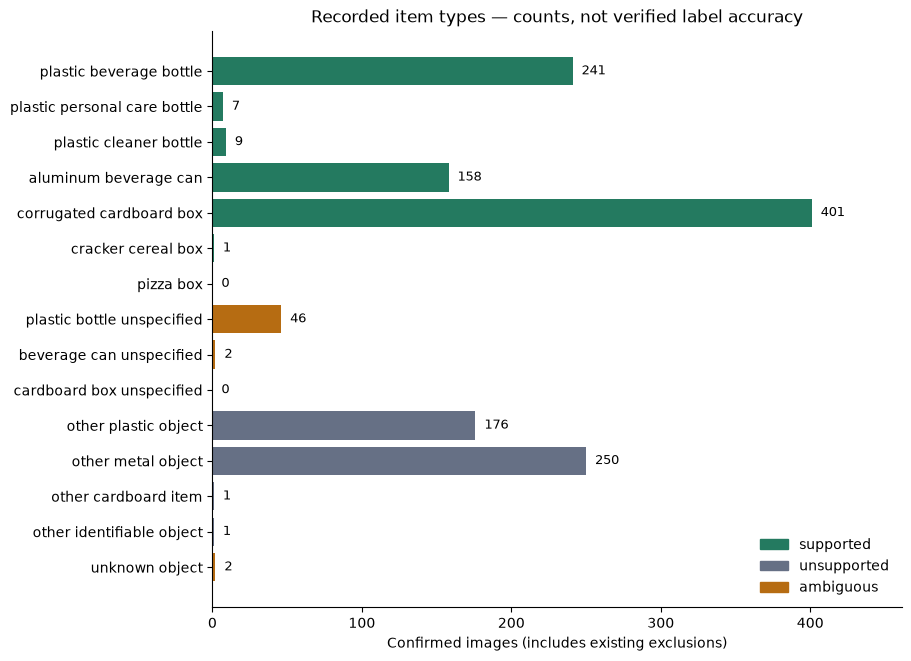

In [9]:
check_results_snapshot()
results_scope_rows = []
for material in (*SOURCE_LABELS, "Overall"):
    population = results_confirmed if material == "Overall" else results_confirmed.loc[
        results_confirmed["original_label"].eq(material)]
    row = {"Original material": material, "Confirmed": len(population)}
    for scope in SCOPE_STATUSES:
        count = int(population["scope_status"].eq(scope).sum())
        row[scope + " n"] = count
        row[scope + " %"] = results_percent(count, len(population))
    results_scope_rows.append(row)
results_scope = pd.DataFrame(results_scope_rows)
results_table("Recorded scope overall and by original material", results_scope)

results_item_rows = []
for item, (required_material, scope) in ITEM_CRITERIA.items():
    population = results_confirmed.loc[results_confirmed["item_type"].eq(item)]
    row = {
        "Item type": item, "Fixed scope": scope, "Count": len(population),
        "% of all confirmed": results_percent(len(population), len(results_confirmed)),
    }
    row.update({material: int(population["original_label"].eq(material).sum())
                for material in SOURCE_LABELS})
    results_item_rows.append(row)
results_items = pd.DataFrame(results_item_rows)
results_table("All established item types (counts by original material)", results_items)

results_colors = {"supported": "#247a60", "unsupported": "#667085", "ambiguous": "#b66c12"}
fig, ax = plt.subplots(figsize=(9, 6.5), layout="constrained")
item_positions = list(range(len(results_items)))
ax.barh(item_positions, results_items["Count"],
        color=[results_colors[s] for s in results_items["Fixed scope"]])
ax.set_yticks(item_positions, results_items["Item type"].str.replace("_", " "))
ax.invert_yaxis()
ax.set_xlabel("Confirmed images (includes existing exclusions)")
ax.set_title("Recorded item types — counts, not verified label accuracy")
largest_count = max(int(results_items["Count"].max()), 1)
ax.set_xlim(0, largest_count * 1.15)
for position, count in enumerate(results_items["Count"]):
    ax.text(count + largest_count * 0.015, position, str(count), va="center", fontsize=9)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=color, label=scope) for scope, color in results_colors.items()],
          loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
display(fig)
plt.close(fig)


## Existing subsets, exclusions, and material-label differences

“Excluded (no subset)” is a display group for records already excluded from experiments; it is not a new split. Scope counts below describe annotations within the existing assignments and do not propose a new training population. Material differences compare two recorded labels; neither is independently established as correct by this analysis.

In [10]:
check_results_snapshot()
results_partitions = ("train", "validation", "test", "Excluded (no subset)")
results_partitioned = results_df.assign(
    partition=results_df["subset"].where(
        results_df["excluded"].ne("true"), "Excluded (no subset)"))
results_partition_rows = []
for partition in results_partitions:
    population = results_partitioned.loc[results_partitioned["partition"].eq(partition)]
    confirmed = population.loc[population["review_status"].eq("confirmed")]
    row = {"Existing assignment": partition, "All records": len(population),
           "Confirmed": len(confirmed), "Remaining": len(population) - len(confirmed)}
    row.update({scope: int(confirmed["scope_status"].eq(scope).sum())
                for scope in SCOPE_STATUSES})
    results_partition_rows.append(row)
results_partitions_table = pd.DataFrame(results_partition_rows)
results_table("Existing assignments and confirmed scope", results_partitions_table)
results_table("Original material by existing assignment (all review records)",
              pd.crosstab(results_partitioned["partition"],
                          results_partitioned["original_label"])
              .reindex(index=results_partitions, columns=SOURCE_LABELS, fill_value=0)
              .rename_axis("Existing assignment").reset_index())

results_supported_types = [item for item, (_, scope) in ITEM_CRITERIA.items()
                           if scope == "supported"]
results_supported_partitions = pd.crosstab(
    results_partitioned.loc[results_partitioned["review_status"].eq("confirmed"), "item_type"],
    results_partitioned.loc[results_partitioned["review_status"].eq("confirmed"), "partition"]
).reindex(index=results_supported_types, columns=results_partitions, fill_value=0)
results_table("Supported item representation by existing assignment",
              results_supported_partitions.rename_axis("Item type").reset_index())

results_example_columns = [
    "path", "original_label", "reviewed_material_label", "item_type",
    "scope_status", "subset", "excluded", "reason",
]
results_table("Previously excluded records (decisions and exclusion remain separate)",
              results_df.loc[results_df["excluded"].eq("true"), results_example_columns])
results_missing_material = results_confirmed["reviewed_material_label"].eq("")
results_changed_material = results_confirmed.loc[
    ~results_missing_material
    & results_confirmed["reviewed_material_label"].ne(results_confirmed["original_label"])
]
display(Markdown(
    f"**{len(results_changed_material):,}** confirmed rows "
    f"({results_percent(len(results_changed_material), len(results_confirmed))}) have a "
    f"recorded material different from the original label. "
    f"**{int(results_missing_material.sum()):,}** have no reviewed material recorded; "
    "blank labels are reported separately, not counted as relabelings."
))
results_table("Original → reviewed material (confirmed rows)",
              pd.crosstab(results_confirmed["original_label"],
                          results_confirmed["reviewed_material_label"].replace("", "(not recorded)"))
              .reindex(index=SOURCE_LABELS,
                       columns=(*MATERIAL_LABELS, "(not recorded)"), fill_value=0)
              .rename_axis("Original material").reset_index())
results_table("Rows with different recorded materials",
              results_changed_material[results_example_columns])


**Existing assignments and confirmed scope**

Existing assignment,All records,Confirmed,Remaining,supported,unsupported,ambiguous
train,905,905,0,569,302,34
validation,194,194,0,129,58,7
test,193,193,0,118,67,8
Excluded (no subset),3,3,0,1,1,1


**Original material by existing assignment (all review records)**

original_label,Existing assignment,plastic,metal,cardboard
,train,336,287,282
,validation,72,61,61
,test,72,61,60
,Excluded (no subset),2,1,0


**Supported item representation by existing assignment**

partition,Item type,train,validation,test,Excluded (no subset)
,plastic_beverage_bottle,158,44,38,1
,plastic_personal_care_bottle,5,2,0,0
,plastic_cleaner_bottle,8,1,0,0
,aluminum_beverage_can,117,21,20,0
,corrugated_cardboard_box,280,61,60,0
,cracker_cereal_box,1,0,0,0
,pizza_box,0,0,0,0


... (3 outputs left out)

**Original → reviewed material (confirmed rows)**

reviewed_material_label,Original material,plastic,metal,cardboard,paper,glass,trash,(not recorded)
,plastic,480,1,0,0,1,0,0
,metal,1,408,0,0,1,0,0
,cardboard,0,0,403,0,0,0,0


**Rows with different recorded materials**

path,original_label,reviewed_material_label,item_type,scope_status,subset,excluded,reason
metal/metal14.jpg,metal,plastic,plastic_beverage_bottle,supported,test,false,
metal/metal91.jpg,metal,glass,other_identifiable_object,unsupported,,true,glass bottle
plastic/plastic112.jpg,plastic,metal,aluminum_beverage_can,supported,train,false,
plastic/plastic332.jpg,plastic,glass,unknown_object,ambiguous,,true,glass bottle


## Annotation quality: ambiguity and records to inspect again

Schema consistency does **not** establish the correctness of a label or the adequacy of an uncertainty explanation. The following transparent checks flag possible conflicts between notes and the fixed definitions. They do not read images, assign replacement labels, or resolve a decision. They are a targeted checklist, not an exhaustive accuracy audit.

The five paths from the previous audit remain visible even after a correction. “Original trigger no longer present” only describes the current fields; it does **not** certify that a corrected annotation is correct. Recurring short object descriptions such as “milk bottle”, “oil bottle”, and “protein bottle” identify an object or use but do not clearly explain why its supported subtype is uncertain. They need human clarification against the criteria established **before** test inspection. Do not infer a new scope from these phrases alone.

To inspect a listed image, use the existing panel: select its **original category**, choose **Confirmed** or **All**, and find the filename. Use **Edit confirmed → Preview correction → authorize → Save correction** only if you decide a correction is warranted. For a test image, inspect without predictions and keep any findings limited to annotation/documentation.

In [11]:
check_results_snapshot()


def annotation_concerns(row):
    """Targeted note/criterion checks only; no image-based judgments."""
    note = row["reason"].strip().casefold()
    concerns = []
    if row["item_type"] == "aluminum_beverage_can" and re.search(r"\b(steel|tin)\b", note):
        concerns.append("Aluminum item label conflicts with a steel/tin note; inspect material evidence.")
    if row["item_type"] == "beverage_can_unspecified" and (
        "tomato sauce" in note or "oil bottle" in note
    ):
        concerns.append("Note describes a food can or oil bottle; the category requires a beverage can.")
    if row["item_type"] == "unknown_object" and "glass bottle" in note:
        concerns.append("Note names a glass bottle while item type records unknown object.")
    if row["scope_status"] == "unsupported" and note in {"blur", "blurry", "unclear"}:
        concerns.append("Image-quality note alone does not establish an identifiable out-of-scope item.")
    if not row["reviewed_material_label"] and not note:
        concerns.append("Unverified material has no explanatory note.")
    return " ".join(concerns)


results_concerns = results_confirmed[results_example_columns].copy()
results_concerns["Inspection prompt"] = results_confirmed.apply(annotation_concerns, axis=1)
results_concerns = results_concerns.loc[results_concerns["Inspection prompt"].ne("")]
results_table("Current potential inconsistencies (not automatic corrections)", results_concerns)

results_audit_paths = (
    "metal/metal254.jpg", "metal/metal1.jpg", "plastic/plastic68.jpg",
    "plastic/plastic332.jpg", "cardboard/cardboard279.jpg",
)
results_watch_rows = []
for path in results_audit_paths:
    matches = results_df.loc[results_df["path"].eq(path)]
    if matches.empty:
        results_watch_rows.append({"path": path, "Check status": "Missing — inspect manifest integrity"})
        continue
    row = matches.iloc[0]
    concern = annotation_concerns(row)
    watch = row[results_example_columns].to_dict()
    watch["review_status"] = row["review_status"]
    watch["Check status"] = (
        "Inspect: " + concern if concern
        else "Original trigger no longer present; label not independently verified"
    )
    results_watch_rows.append(watch)
results_watchlist = pd.DataFrame(results_watch_rows)
results_table("Five records retained from the previous audit", results_watchlist)

results_ambiguous = results_confirmed.loc[
    results_confirmed["scope_status"].eq("ambiguous"), results_example_columns].copy()
# Match known terse descriptions only; do not rewrite the original notes.
results_terse_reasons = {
    "milk bottle", "oil bottle", "protein bottle", "extralarge bottle",
    "mayo bottle", "big bottle", "tomato sauce can", "glass bottle",
}
results_ambiguous["Clarify uncertainty explanation"] = (
    results_ambiguous["reason"].str.strip().str.casefold().isin(results_terse_reasons))
results_terse_count = int(results_ambiguous["Clarify uncertainty explanation"].sum())
display(Markdown(
    f"**{len(results_ambiguous):,} ambiguous annotations**; "
    f"**{int(results_ambiguous['reason'].str.strip().eq('').sum())}** blank explanations. "
    f"**{results_terse_count:,}** match the targeted list of terse object descriptions. "
    "Other notes are not automatically certified as adequate."
))
results_table("Ambiguous item types and exact recorded reasons",
              results_ambiguous.groupby(["item_type", "reason"], dropna=False)
              .size().rename("Count").reset_index().sort_values(
                  ["Count", "item_type", "reason"], ascending=[False, True, True]))
results_table("All ambiguous records — paths and original notes for manual inspection",
              results_ambiguous.sort_values(["item_type", "reason", "path"]), collapsed=True)

results_noted = results_confirmed.loc[
    results_confirmed["reason"].str.strip().ne("")].copy()
results_noted["Note (case/whitespace grouped for display only)"] = (
    results_noted["reason"].str.strip().str.casefold())
results_note_key = "Note (case/whitespace grouped for display only)"
results_repeated_notes = results_noted.groupby(results_note_key).size()
results_repeated_keys = results_repeated_notes.loc[results_repeated_notes.gt(1)].index
results_table("Recurring notes by recorded item and scope (no notes changed)",
              results_noted.loc[results_noted[results_note_key].isin(results_repeated_keys)]
              .groupby([results_note_key, "item_type", "scope_status"])
              .size().rename("Count").reset_index())


**Current potential inconsistencies (not automatic corrections)**

path,original_label,reviewed_material_label,item_type,scope_status,subset,excluded,reason,Inspection prompt
cardboard/cardboard279.jpg,cardboard,cardboard,other_cardboard_item,unsupported,train,false,blur,Image-quality note alone does not establish an identifiable out-of-scope item.
metal/metal1.jpg,metal,metal,beverage_can_unspecified,ambiguous,train,false,Tomato sauce can,Note describes a food can or oil bottle; the category requires a beverage can.
metal/metal254.jpg,metal,metal,aluminum_beverage_can,supported,train,false,steel,Aluminum item label conflicts with a steel/tin note; inspect material evidence.
plastic/plastic332.jpg,plastic,glass,unknown_object,ambiguous,,true,glass bottle,Note names a glass bottle while item type records unknown object.
plastic/plastic68.jpg,plastic,plastic,beverage_can_unspecified,ambiguous,test,false,oil bottle,Note describes a food can or oil bottle; the category requires a beverage can.


**Five records retained from the previous audit**

path,original_label,reviewed_material_label,item_type,scope_status,subset,excluded,reason,review_status,Check status
metal/metal254.jpg,metal,metal,aluminum_beverage_can,supported,train,false,steel,confirmed,Inspect: Aluminum item label conflicts with a steel/tin note; inspect material evidence.
metal/metal1.jpg,metal,metal,beverage_can_unspecified,ambiguous,train,false,Tomato sauce can,confirmed,Inspect: Note describes a food can or oil bottle; the category requires a beverage can.
plastic/plastic68.jpg,plastic,plastic,beverage_can_unspecified,ambiguous,test,false,oil bottle,confirmed,Inspect: Note describes a food can or oil bottle; the category requires a beverage can.
plastic/plastic332.jpg,plastic,glass,unknown_object,ambiguous,,true,glass bottle,confirmed,Inspect: Note names a glass bottle while item type records unknown object.
cardboard/cardboard279.jpg,cardboard,cardboard,other_cardboard_item,unsupported,train,false,blur,confirmed,Inspect: Image-quality note alone does not establish an identifiable out-of-scope item.


**50 ambiguous annotations**; **0** blank explanations. **48** match the targeted list of terse object descriptions. Other notes are not automatically certified as adequate.

**Ambiguous item types and exact recorded reasons**

item_type,reason,Count
plastic_bottle_unspecified,milk bottle,33
plastic_bottle_unspecified,oil bottle,3
plastic_bottle_unspecified,protein bottle,3
plastic_bottle_unspecified,Milk bottle,2
beverage_can_unspecified,Tomato sauce can,1
beverage_can_unspecified,oil bottle,1
plastic_bottle_unspecified,Big bottle,1
plastic_bottle_unspecified,Extralarge bottle,1
plastic_bottle_unspecified,Not clear but a bottle,1
plastic_bottle_unspecified,Oil bottle,1


**All ambiguous records — paths and original notes for manual inspection**

path,original_label,reviewed_material_label,item_type,scope_status,subset,excluded,reason,Clarify uncertainty explanation
metal/metal1.jpg,metal,metal,beverage_can_unspecified,ambiguous,train,false,Tomato sauce can,True
plastic/plastic68.jpg,plastic,plastic,beverage_can_unspecified,ambiguous,test,false,oil bottle,True
plastic/plastic27.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,Big bottle,True
plastic/plastic15.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,Extralarge bottle,True
plastic/plastic70.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,Milk bottle,True
plastic/plastic87.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,Milk bottle,True
plastic/plastic78.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,validation,false,Not clear but a bottle,False
plastic/plastic40.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,Oil bottle,True
plastic/plastic259.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,mayo bottle,True
plastic/plastic137.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,milk bottle,True


**Recurring notes by recorded item and scope (no notes changed)**

Note (case/whitespace grouped for display only),item_type,scope_status,Count
glass bottle,other_identifiable_object,unsupported,1
glass bottle,unknown_object,ambiguous,1
milk bottle,plastic_bottle_unspecified,ambiguous,35
oil bottle,beverage_can_unspecified,ambiguous,1
oil bottle,other_plastic_object,unsupported,1
oil bottle,plastic_bottle_unspecified,ambiguous,4
protein bottle,plastic_bottle_unspecified,ambiguous,3
steel,aluminum_beverage_can,supported,1
steel,other_metal_object,unsupported,141


## Representative recorded annotations

These examples are selected deterministically from the current CSV: the first path for each listed item type, if present. They illustrate how fields are used; they are not a random sample, a new image inspection, or independently verified reference labels. The complete ambiguous and flagged lists above provide the inspection queue.

In [12]:
check_results_snapshot()
results_example_types = (
    "corrugated_cardboard_box", "plastic_beverage_bottle",
    "other_plastic_object", "plastic_bottle_unspecified",
)
results_examples = pd.concat([
    results_confirmed.loc[results_confirmed["item_type"].eq(item)]
    .sort_values("path").head(1)
    for item in results_example_types
], ignore_index=True)
results_table("Examples from the saved manual decisions",
              results_examples[results_example_columns])


**Examples from the saved manual decisions**

path,original_label,reviewed_material_label,item_type,scope_status,subset,excluded,reason
cardboard/cardboard1.jpg,cardboard,cardboard,corrugated_cardboard_box,supported,train,false,
metal/metal14.jpg,metal,plastic,plastic_beverage_bottle,supported,test,false,
plastic/plastic102.jpg,plastic,plastic,other_plastic_object,unsupported,train,false,
plastic/plastic137.jpg,plastic,plastic,plastic_bottle_unspecified,ambiguous,train,false,milk bottle


## Guidance and draft text for Milestone 4

**Section 6.4:** use the generated paragraph and tables to distinguish TrashNet's material classes from WasteWise's supported item types. Report coverage and limitations as findings from the recorded manual annotations. Scope is not recycling eligibility, annotation correctness, or permission to alter the experiment population.

**Section 6.7:** **retain the existing image normalization and preprocessing discussion unchanged.** Append the generated item-level paragraph below that discussion; it supplements the earlier preprocessing evidence. It does not describe new preprocessing, relabeling of training targets, filtering, or a new experiment.

The draft below is regenerated from this snapshot. Conclusions about precise item coverage remain provisional while ambiguity or note/label conflicts remain. Even after these are resolved, a confirmation is not an independent visual validation. No inter-reviewer agreement or model performance can be inferred from this table.

In [13]:
check_results_snapshot()
results_total = len(results_confirmed)
results_scope_totals = results_confirmed["scope_status"].value_counts()
results_supported_n = int(results_scope_totals.get("supported", 0))
results_unsupported_n = int(results_scope_totals.get("unsupported", 0))
results_ambiguous_n = int(results_scope_totals.get("ambiguous", 0))
results_reviewers_n = results_confirmed["reviewer"].nunique()
results_material_sentences = []
for row in results_scope_rows[:-1]:
    results_material_sentences.append(
        f"{row['Original material']}: {row['Confirmed']:,} confirmed, "
        f"{row['supported n']:,} supported ({row['supported %']}), "
        f"{row['unsupported n']:,} unsupported ({row['unsupported %']}), "
        f"{row['ambiguous n']:,} ambiguous ({row['ambiguous %']})"
    )
results_supported_counts = results_items.loc[
    results_items["Fixed scope"].eq("supported")].set_index("Item type")["Count"]
results_coverage_text = "; ".join(
    f"{item.replace('_', ' ')}: {int(count):,}"
    for item, count in results_supported_counts.items()
)
results_zero_types = results_supported_counts.loc[results_supported_counts.eq(0)].index.tolist()
results_zero_text = (
    "No confirmed examples were recorded for "
    + ", ".join(item.replace("_", " ") for item in results_zero_types) + ". "
    if results_zero_types else "Every supported type has at least one recorded example. "
)
results_top = results_supported_counts.sort_values(ascending=False, kind="stable").head(3)
results_concentration_text = (
    f"The three largest supported item categories account for {int(results_top.sum()):,} "
    f"of {results_supported_n:,} supported annotations "
    f"({results_percent(int(results_top.sum()), results_supported_n)}). "
    if results_supported_n else "There are no confirmed supported examples in this snapshot. "
)
results_partition_text = "; ".join(
    f"{row['Existing assignment']}: {row['All records']:,} records "
    f"({row['supported']:,} supported, {row['unsupported']:,} unsupported, "
    f"{row['ambiguous']:,} ambiguous, {row['Remaining']:,} unconfirmed)"
    for row in results_partition_rows
)
results_zero_test_types = results_supported_partitions.index[
    results_supported_partitions["test"].eq(0)].tolist()
results_test_coverage_text = (
    "The existing test subset has no confirmed supported examples of "
    + ", ".join(item.replace("_", " ") for item in results_zero_test_types)
    + "; this is a documentation finding, not a basis for altering evaluation. "
    if results_zero_test_types else ""
)
results_provisional_text = (
    f"Precise coverage remains provisional: {results_ambiguous_n:,} recorded decisions are "
    f"ambiguous, {len(results_concerns):,} records trigger the targeted inconsistency checks, "
    f"and {results_terse_count:,} ambiguous notes match terse descriptions needing clarification. "
    "These are overlapping checks and their counts must not be added. "
    if results_ambiguous_n or len(results_concerns) else
    "No ambiguity or targeted inconsistency trigger remains in this snapshot; this does not "
    "establish independently verified labels. "
)
results_pending_text = (
    f"{len(results_df) - results_total:,} records still await confirmation; scope percentages "
    "describe the confirmed rows only. "
    if len(results_df) != results_total else ""
)
display(Markdown(
    "### Draft supplement for Section 6.4 — item representation\n\n"
    f"The manual review manifest contains {len(results_df):,} images from the original plastic, "
    f"metal and cardboard folders, of which {results_total:,} are confirmed. "
    f"The review population covers {len(results_df):,} of the {len(inventory_rows):,} inventory "
    f"images; the other {len(inventory_rows) - len(results_df):,} images were outside this review. "
    + results_pending_text
    + f"Recorded scope is supported for {results_supported_n:,} images "
    f"({results_percent(results_supported_n, results_total)}), unsupported for "
    f"{results_unsupported_n:,} ({results_percent(results_unsupported_n, results_total)}), and "
    f"ambiguous for {results_ambiguous_n:,} ({results_percent(results_ambiguous_n, results_total)}). "
    "By original material: " + "; ".join(results_material_sentences) + ".\n\n"
    "Recorded supported item counts are: " + results_coverage_text + ". "
    + results_zero_text + results_concentration_text
    + "These annotations document uneven item coverage; a material-folder label alone does not "
    "demonstrate coverage of the supported WasteWise object types. "
    + results_provisional_text
    + f"The confirmed rows contain {results_reviewers_n:,} distinct recorded reviewer name(s); "
    "reviewer names do not establish independent agreement. These statistics describe human "
    "decisions and do not measure label accuracy, recycling eligibility or model performance.\n\n"
    "### Draft supplement for Section 6.7 — after existing normalization/preprocessing text\n\n"
    "The item-level annotation layer adds documentation of item identity, scope and review "
    "uncertainty to the existing preparation records. It does not change the original images, "
    "material training targets, normalization, preprocessing, duplicate groups, exclusions or "
    "saved assignments. Within the reviewed population, the existing assignments are: "
    + results_partition_text + ". "
    + results_test_coverage_text
    + f"{len(results_changed_material):,} confirmed rows "
    f"({results_percent(len(results_changed_material), results_total)}) record a different "
    f"reviewed material from their original label, while {int(results_missing_material.sum()):,} "
    "have no reviewed material recorded. Differences are annotation evidence requiring human "
    "interpretation, not independently verified corrections to the dataset. Supported item "
    "scope does not reverse an existing exclusion, and unsupported scope does not automatically "
    "exclude an image from material-classifier training. "
    + results_provisional_text
    + "Test-image annotations are used only for manual review and dataset documentation, without "
    "predictions; they do not inform model selection, threshold tuning, retraining or changes "
    "to the evaluation procedure."
))
check_results_snapshot()
display(Markdown("**Read-only analysis complete.** Refresh all cells in this section after saving a correction."))


### Draft supplement for Section 6.4 — item representation

The manual review manifest contains 1,295 images from the original plastic, metal and cardboard folders, of which 1,295 are confirmed. The review population covers 1,295 of the 2,527 inventory images; the other 1,232 images were outside this review. Recorded scope is supported for 817 images (63.09%), unsupported for 428 (33.05%), and ambiguous for 50 (3.86%). By original material: plastic: 482 confirmed, 257 supported (53.32%), 176 unsupported (36.51%), 49 ambiguous (10.17%); metal: 410 confirmed, 158 supported (38.54%), 251 unsupported (61.22%), 1 ambiguous (0.24%); cardboard: 403 confirmed, 402 supported (99.75%), 1 unsupported (0.25%), 0 ambiguous (0.00%).

Recorded supported item counts are: plastic beverage bottle: 241; plastic personal care bottle: 7; plastic cleaner bottle: 9; aluminum beverage can: 158; corrugated cardboard box: 401; cracker cereal box: 1; pizza box: 0. No confirmed examples were recorded for pizza box. The three largest supported item categories account for 800 of 817 supported annotations (97.92%). These annotations document uneven item coverage; a material-folder label alone does not demonstrate coverage of the supported WasteWise object types. Precise coverage remains provisional: 50 recorded decisions are ambiguous, 5 records trigger the targeted inconsistency checks, and 48 ambiguous notes match terse descriptions needing clarification. These are overlapping checks and their counts must not be added. The confirmed rows contain 1 distinct recorded reviewer name(s); reviewer names do not establish independent agreement. These statistics describe human decisions and do not measure label accuracy, recycling eligibility or model performance.

### Draft supplement for Section 6.7 — after existing normalization/preprocessing text

The item-level annotation layer adds documentation of item identity, scope and review uncertainty to the existing preparation records. It does not change the original images, material training targets, normalization, preprocessing, duplicate groups, exclusions or saved assignments. Within the reviewed population, the existing assignments are: train: 905 records (569 supported, 302 unsupported, 34 ambiguous, 0 unconfirmed); validation: 194 records (129 supported, 58 unsupported, 7 ambiguous, 0 unconfirmed); test: 193 records (118 supported, 67 unsupported, 8 ambiguous, 0 unconfirmed); Excluded (no subset): 3 records (1 supported, 1 unsupported, 1 ambiguous, 0 unconfirmed). The existing test subset has no confirmed supported examples of plastic personal care bottle, plastic cleaner bottle, cracker cereal box, pizza box; this is a documentation finding, not a basis for altering evaluation. 4 confirmed rows (0.31%) record a different reviewed material from their original label, while 0 have no reviewed material recorded. Differences are annotation evidence requiring human interpretation, not independently verified corrections to the dataset. Supported item scope does not reverse an existing exclusion, and unsupported scope does not automatically exclude an image from material-classifier training. Precise coverage remains provisional: 50 recorded decisions are ambiguous, 5 records trigger the targeted inconsistency checks, and 48 ambiguous notes match terse descriptions needing clarification. These are overlapping checks and their counts must not be added. Test-image annotations are used only for manual review and dataset documentation, without predictions; they do not inform model selection, threshold tuning, retraining or changes to the evaluation procedure.

**Read-only analysis complete.** Refresh all cells in this section after saving a correction.